<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 9: Multilayer Perceptron Implementation
This notebook demonstrates a complete end-to-end Multilayer Perceptron (MLP) classifier using Keras to predict customer churn.
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

```markdown
## Task 1: Generate & Pre-process Churn Dataset
We will create a synthetic dataset representing customer features and their churn label.
```

In [2]:
# 1. Create Synthetic Customer Churn Dataset
n_samples = 1000

tenure = np.random.randint(1, 72, size=n_samples)
monthly_charges = np.random.uniform(20.0, 120.0, size=n_samples)
contract_type = np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples)
complaints = np.random.choice([0, 1], size=n_samples, p=[0.7, 0.3])
data_usage = np.random.uniform(0.5, 50.0, size=n_samples)

# Logic to generate synthetic churn label based on rules
# Churn is highly likely if contract is month-to-month, complaints are high, and charges are high relative to tenure
churn_prob = 1 / (1 + np.exp(-(-2.0 - 0.05*tenure + 0.02*monthly_charges + 1.5*(contract_type == 'Month-to-month') + 2.0*complaints)))
churn = np.random.binomial(1, churn_prob)

df = pd.DataFrame({
    'Tenure': tenure,
    'MonthlyCharges': monthly_charges,
    'ContractType': contract_type,
    'Complaints': complaints,
    'DataUsage': data_usage,
    'Churn': churn
})

display(df.head())

,Tenure,MonthlyCharges,ContractType,Complaints,DataUsage,Churn
0,52,105.569647,One year,0,9.940936,0
1,15,103.021986,One year,0,17.679587,0
2,61,59.718353,Two year,1,27.588257,0
3,21,86.808514,Month-to-month,0,49.592758,0
4,24,40.498430,One year,0,33.377985,0


In [3]:
# Encoding Categorical fields and Scaling Numeric fields
# Encode contract type
le = LabelEncoder()
df['ContractType'] = le.fit_transform(df['ContractType'])

X = df.drop('Churn', axis=1)
y = df['Churn']

# Split Dataset into Train and Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale Numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training shape: {X_train_scaled.shape}, Testing shape: {X_test_scaled.shape}")

Training shape: (800, 5), Testing shape: (200, 5)


```markdown
## Tasks 2 & 3: Build & Train the MLP Model
We create an MLP with two hidden layers using ReLU activation, compiled with Binary Cross-Entropy and the Adam optimizer.
```

In [7]:
def build_model(input_dim, hidden_units=[32, 16]):
    model = Sequential()
    # Input layer and first hidden layer
    model.add(Dense(hidden_units[0], activation='relu', input_shape=(input_dim,)))
    # Second hidden layer
    for units in hidden_units[1:]:
        model.add(Dense(units, activation='relu'))
    # Output layer for binary classification
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(learning_rate=0.005),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

model = build_model(X_train_scaled.shape[1], hidden_units=[32, 16])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

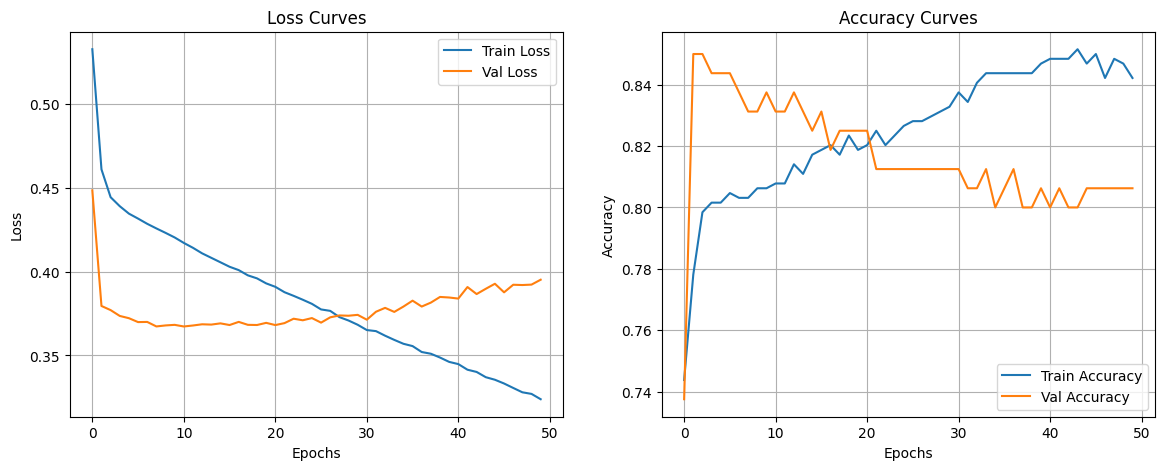

In [8]:
# Train the model
history = model.fit(X_train_scaled, y_train,
                    validation_split=0.2,
                    epochs=50,
                    batch_size=32,
                    verbose=0)

# Plot Training & Validation Loss/Accuracy Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

```markdown
## Task 4: Evaluation and Metrics
Evaluate accuracy, precision, recall, F1, and show the confusion matrix on test data.
```

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Classification Metrics:
Accuracy:  0.7800
Precision: 0.6512
Recall:    0.4912
F1 Score:  0.5600


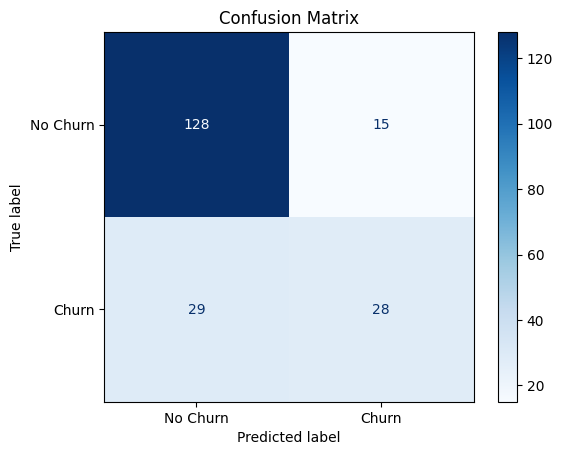

In [9]:
# Predict probabilities and convert to class labels
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("Classification Metrics:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

```markdown
## Task 5: Varying Hidden-Layer Width
Let's train different MLP configurations to study the impact of layer width and depth on overall test performance.
```

In [10]:
configurations = {
    "Small [8, 4]": [8, 4],
    "Medium [32, 16]": [32, 16],
    "Large [128, 64, 32]": [128, 64, 32]
}

for name, layers in configurations.items():
    temp_model = build_model(X_train_scaled.shape[1], hidden_units=layers)
    temp_model.fit(X_train_scaled, y_train, epochs=40, batch_size=32, verbose=0)

    preds = (temp_model.predict(X_test_scaled) > 0.5).astype(int).flatten()
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    print(f"Configuration: {name:20} -> Test Accuracy: {acc:.4f} | Test F1: {f1:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Configuration: Small [8, 4]         -> Test Accuracy: 0.8150 | Test F1: 0.6263


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Configuration: Medium [32, 16]      -> Test Accuracy: 0.8150 | Test F1: 0.6263


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Configuration: Large [128, 64, 32]  -> Test Accuracy: 0.7650 | Test F1: 0.5437
